<a href="https://colab.research.google.com/github/laboratoriodecodigos/Colab-Python/blob/main/Yolo_5_cosas_que_puede_hacer.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# YOLO no solo detecta: 5 cosas que puede hacer con 1 línea
**Laboratorio de Códigos** · Ultralytics YOLO: detectar, segmentar, pose, clasificar y seguir

Usa **el mismo video** para las 5 tareas: así el contraste se ve claro. Mejor uno con personas y objetos (calle, parque, deporte), de 5–15 s. Activa GPU T4.

In [ ]:
!pip install -q ultralytics

In [ ]:
from google.colab import files
subido = files.upload()
VIDEO_IN = next(iter(subido))

Saving 1887-151131664_medium.mp4 to 1887-151131664_medium.mp4


In [ ]:
import cv2, time, numpy as np, matplotlib.pyplot as plt
from ultralytics import YOLO

def cargar(v26, v11):
    """Intenta YOLO26; si tu versión de Ultralytics no lo tiene, usa YOLO11."""
    try:
        return YOLO(v26)
    except Exception:
        return YOLO(v11)

modelos = {
    "1. Detectar":    cargar("yolo26n.pt", "yolo11n.pt"),
    "2. Segmentar":   cargar("yolo26n-seg.pt", "yolo11n-seg.pt"),
    "3. Pose":        cargar("yolo26n-pose.pt", "yolo11n-pose.pt"),
    "4. Clasificar":  cargar("yolo26n-cls.pt", "yolo11n-cls.pt"),
}

# Cuadro de la mitad del video para las 4 primeras tareas
cap = cv2.VideoCapture(VIDEO_IN)
N = int(cap.get(cv2.CAP_PROP_FRAME_COUNT)); fps = cap.get(cv2.CAP_PROP_FPS) or 30
cap.set(cv2.CAP_PROP_POS_FRAMES, N // 2); ok, cuadro = cap.read(); cap.release()
print(f"Video: {N} cuadros a {fps:.0f} fps")

Video: 300 cuadros a 30 fps


## Tareas 1 a 4: la misma línea, otro modelo

In [ ]:
resultados, resumen = {}, {}
for nombre, m in modelos.items():
    t0 = time.perf_counter()
    r = m(cuadro, verbose=False)[0]           # la misma línea para todas las tareas
    ms = (time.perf_counter() - t0) * 1000
    resultados[nombre] = r.plot()[:, :, ::-1]
    if r.probs is not None:                   # clasificación: top 3 de la imagen completa
        top = [(r.names[int(i)], float(r.probs.data[int(i)])) for i in r.probs.top5[:3]]
        resumen[nombre] = {"top3": [f"{n} {p*100:.0f}%" for n, p in top], "ms": round(ms, 1)}
    else:
        clases = [r.names[int(c)] for c in r.boxes.cls]
        resumen[nombre] = {"objetos": len(clases), "clases": sorted(set(clases)), "ms": round(ms, 1)}
for k, v in resumen.items():
    print(k, v)

1. Detectar {'objetos': 10, 'clases': ['chair', 'handbag', 'person'], 'ms': 215.8}
2. Segmentar {'objetos': 7, 'clases': ['backpack', 'chair', 'person'], 'ms': 329.3}
3. Pose {'objetos': 6, 'clases': ['person'], 'ms': 408.7}
4. Clasificar {'top3': ['turnstile 10%', 'jinrikisha 8%', 'streetcar 6%'], 'ms': 140.8}


## Tarea 5: seguir objetos por todo el video

In [ ]:
# 5. Seguir: el mismo modelo de detección + .track() en todo el video
from collections import defaultdict
rutas = defaultdict(list)
det = cargar("yolo26n.pt", "yolo11n.pt")
cap = cv2.VideoCapture(VIDEO_IN)
t0 = time.perf_counter(); n = 0
while True:
    ok, fr = cap.read()
    if not ok:
        break
    r = det.track(fr, persist=True, tracker="bytetrack.yaml", verbose=False)[0]
    ultimo = fr
    if r.boxes.id is not None:
        for (x1, y1, x2, y2), tid, c in zip(r.boxes.xyxy.cpu().numpy(), r.boxes.id.int().tolist(), r.boxes.cls.int().tolist()):
            rutas[(tid, r.names[c])].append((int((x1 + x2) / 2), int(y2)))
    n += 1
cap.release()

# Dibujar la ruta de cada objeto sobre el último cuadro
lienzo = ultimo.copy()
rng = np.random.default_rng(1)
for (tid, cls), pts in rutas.items():
    if len(pts) < int(fps):               # ignora objetos que aparecen menos de 1 s
        continue
    col = tuple(int(v) for v in rng.integers(60, 255, 3))
    cv2.polylines(lienzo, [np.array(pts, np.int32)], False, col, 4)
    cv2.putText(lienzo, f"#{tid} {cls}", pts[-1], cv2.FONT_HERSHEY_SIMPLEX, 0.8, col, 2)
resultados["5. Seguir"] = lienzo[:, :, ::-1]
largos = {k: v for k, v in rutas.items() if len(v) >= int(fps)}
resumen["5. Seguir"] = {"objetos_seguidos": len(largos), "ms_por_cuadro": round((time.perf_counter() - t0) / n * 1000, 1)}
print(resumen["5. Seguir"])

{'objetos_seguidos': 27, 'ms_por_cuadro': 134.5}


## Las 5 juntas

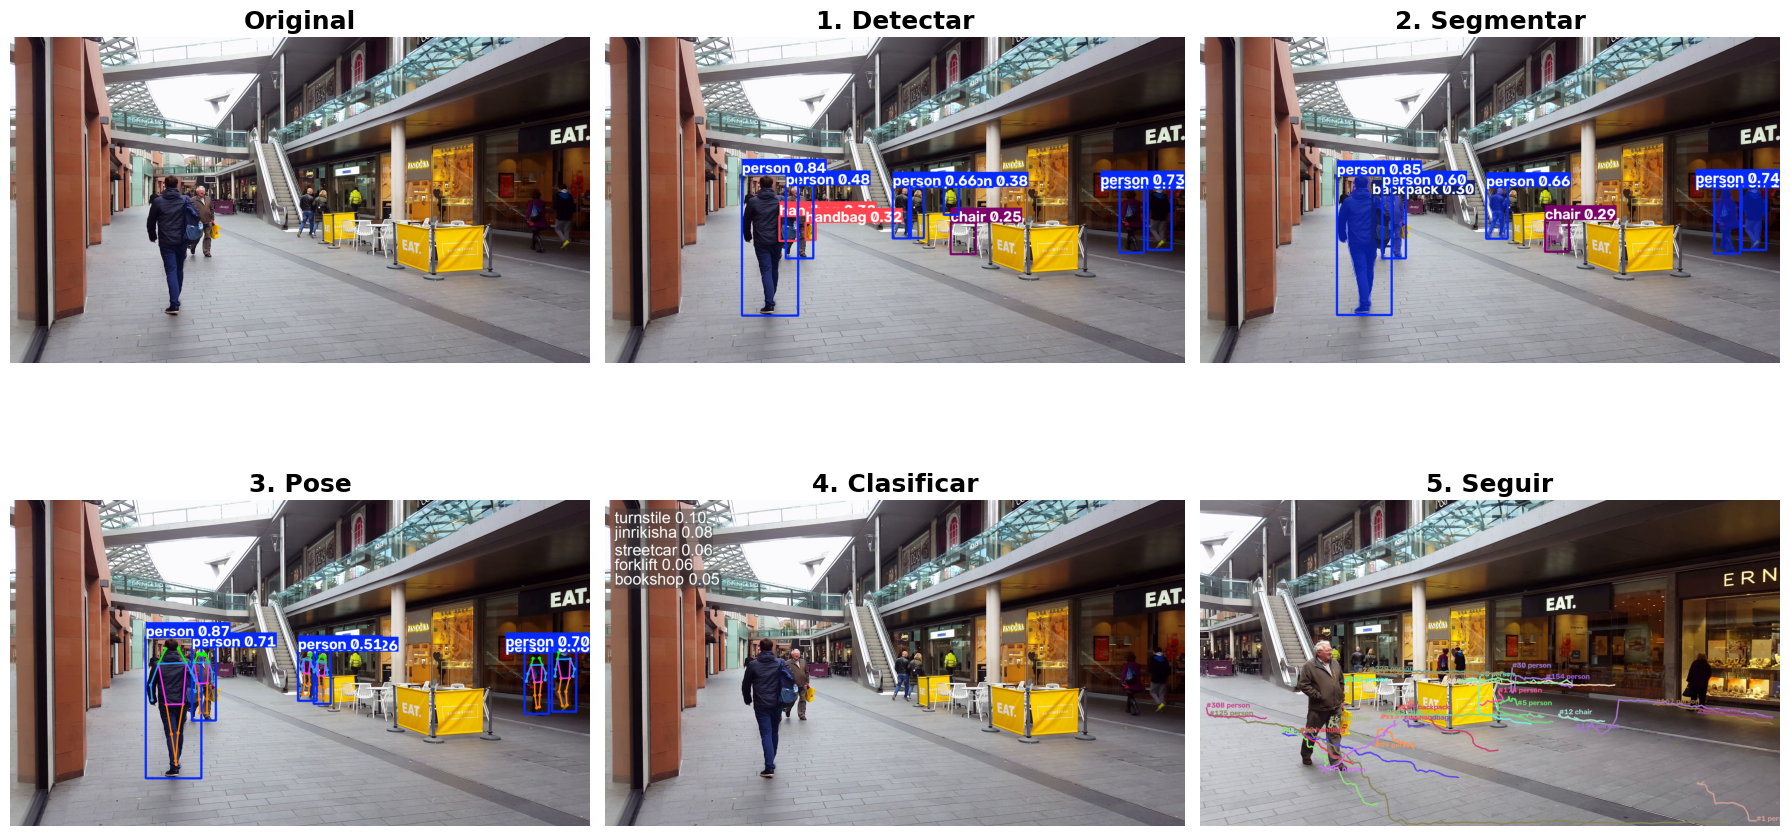

In [ ]:
import json
fig, ax = plt.subplots(2, 3, figsize=(18, 10.5))
ax[0, 0].imshow(cuadro[:, :, ::-1]); ax[0, 0].set_title("Original", fontsize=18, fontweight="bold")
for a, (nombre, img) in zip(ax.flat[1:], resultados.items()):
    a.imshow(img); a.set_title(nombre, fontsize=18, fontweight="bold")
for a in ax.flat: a.axis("off")
plt.tight_layout(); plt.savefig("yolo_5_tareas.png", dpi=150); plt.show()

for nombre, img in resultados.items():
    cv2.imwrite(nombre.split(". ")[1].lower() + ".jpg", img[:, :, ::-1])
json.dump(resumen, open("resumen.json", "w"), ensure_ascii=False, indent=2)

In [ ]:
import cv2
import numpy as np
from collections import defaultdict

# Definir nombres de salida para los videos
videos_salida = {
    "1. Detectar": "detectar.mp4",
    "2. Segmentar": "segmentar.mp4",
    "3. Pose": "pose.mp4",
    "4. Clasificar": "clasificar.mp4",
    "5. Seguir": "seguir.mp4"
}

# Obtener dimensiones correctas abriendo el video
cap_test = cv2.VideoCapture(VIDEO_IN)
ancho = int(cap_test.get(cv2.CAP_PROP_FRAME_WIDTH))
alto = int(cap_test.get(cv2.CAP_PROP_FRAME_HEIGHT))
cap_test.release()

# Si falló la lectura de dimensiones por defecto
if ancho <= 0 or alto <= 0:
    ancho, alto = 1920, 1080

fps_video = int(fps) if 'fps' in locals() and fps > 0 else 25
fourcc = cv2.VideoWriter_fourcc(*'mp4v')

# --- TAREAS 1 A 4: Generar videos fotograma por fotograma ---
for nombre, m in modelos.items():
    print(f"Procesando video para: {nombre}...")
    cap = cv2.VideoCapture(VIDEO_IN)
    out = cv2.VideoWriter(videos_salida[nombre], fourcc, fps_video, (ancho, alto))

    while True:
        ok, fr = cap.read()
        if not ok:
            break

        # Realizar predicción en el cuadro
        r = m(fr, verbose=False)[0]

        # Si es clasificación, dibujamos los textos encima ya que plot() no los superpone individualmente en objetos
        if "Clasificar" in nombre:
            lienzo = fr.copy()
            if r.probs is not None:
                top = [(r.names[int(i)], float(r.probs.data[int(i)])) for i in r.probs.top5[:3]]
                textos = [f"{n} {p*100:.0f}%" for n, p in top]
                for idx, texto in enumerate(textos):
                    cv2.putText(lienzo, texto, (50, 80 + idx * 40), cv2.FONT_HERSHEY_SIMPLEX, 1.2, (0, 255, 0), 3)
            out.write(lienzo)
        else:
            # Para detección, segmentación y pose, plot() devuelve la imagen anotada
            out.write(r.plot())

    cap.release()
    out.release()

# --- TAREA 5: Seguir (Tracking) en todo el video con historial de rutas ---
print("Procesando video para: 5. Seguir...")
cap = cv2.VideoCapture(VIDEO_IN)
out = cv2.VideoWriter(videos_salida["5. Seguir"], fourcc, fps_video, (ancho, alto))
rutas_video = defaultdict(list)
rng = np.random.default_rng(1)

while True:
    ok, fr = cap.read()
    if not ok:
        break

    r = det.track(fr, persist=True, tracker="bytetrack.yaml", verbose=False)[0]
    lienzo = fr.copy()

    if r.boxes.id is not None:
        xyxy = r.boxes.xyxy.cpu().numpy()
        ids = r.boxes.id.int().tolist()
        clases_id = r.boxes.cls.int().tolist()

        for bbox, tid, c in zip(xyxy, ids, clases_id):
            x1, y1, x2, y2 = bbox
            centro_x, pie_y = int((x1 + x2) / 2), int(y2)
            rutas_video[(tid, r.names[c])].append((centro_x, pie_y))

            # Dibujar caja y etiqueta actual
            color = tuple(int(v) for v in rng.integers(60, 255, 3))
            cv2.rectangle(lienzo, (int(x1), int(y1)), (int(x2), int(y2)), color, 2)
            cv2.putText(lienzo, f"#{tid} {r.names[c]}", (int(x1), int(y1) - 10), cv2.FONT_HERSHEY_SIMPLEX, 0.6, color, 2)

    # Dibujar las trayectorias activas acumuladas en el video
    for (tid, cls), pts in rutas_video.items():
        if len(pts) > 1:
            cv2.polylines(lienzo, [np.array(pts, np.int32)], False, (0, 255, 255), 2)

    out.write(lienzo)

cap.release()
out.release()
print("¡Listo! Se han generado los 5 videos individuales exitosamente.")

Procesando video para: 1. Detectar...
Procesando video para: 2. Segmentar...
Procesando video para: 3. Pose...
Procesando video para: 4. Clasificar...
Procesando video para: 5. Seguir...
¡Listo! Se han generado los 5 videos individuales exitosamente.


In [ ]:
import zipfile
from google.colab import files

# Lista de los videos generados
archivos_videos = [
    "detectar.mp4",
    "segmentar.mp4",
    "pose.mp4",
    "clasificar.mp4",
    "seguir.mp4"
]

# Crear un archivo ZIP para descargarlos todos juntos de forma rápida
nombre_zip = "yolo_resultados_videos.zip"
with zipfile.ZipFile(nombre_zip, 'w') as zipf:
    for archivo in archivos_videos:
        try:
            zipf.write(archivo)
            print(f"Agregado {archivo} al archivo ZIP.")
        except FileNotFoundError:
            print(f"Advertencia: No se encontró el archivo {archivo}")

# Iniciar la descarga del archivo ZIP
print("Iniciando la descarga del archivo ZIP...")
files.download(nombre_zip)

Agregado detectar.mp4 al archivo ZIP.
Agregado segmentar.mp4 al archivo ZIP.
Agregado pose.mp4 al archivo ZIP.
Agregado clasificar.mp4 al archivo ZIP.
Agregado seguir.mp4 al archivo ZIP.
Iniciando la descarga del archivo ZIP...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>